## Methodologies Notebook

1) Nx Graph Creation 
2) Transformation from Cyclic Graphs to Tiered DAGs

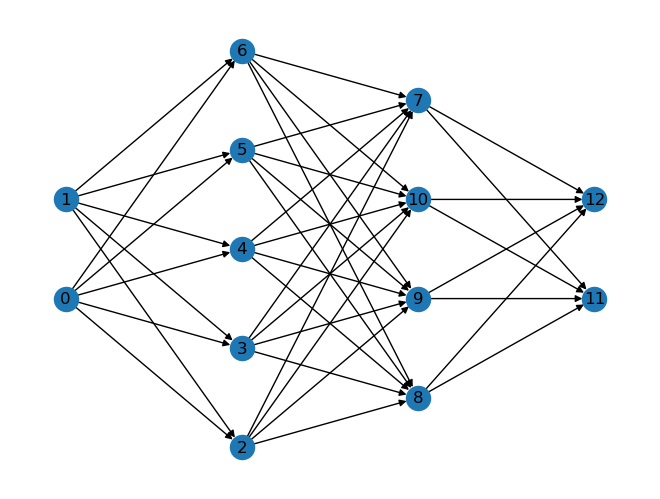

In [ ]:
from src.graph_utils import create_layered_graph
import networkx as nx

layer_sizes = [2, 5, 4, 2]
G, layers = create_layered_graph(layer_sizes)
pos = nx.multipartite_layout(G, subset_key='layer', align='vertical', scale=2)
nx.draw(G, pos, with_labels=True)

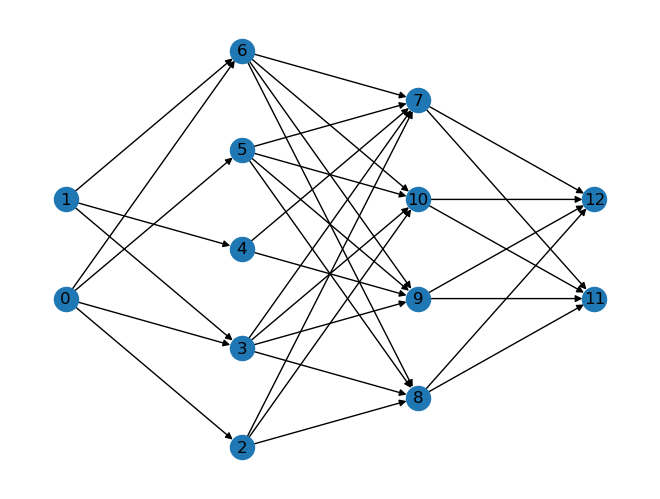

In [ ]:
import numpy as np
from src.graph_utils import assign_properties


G = assign_properties(G, layer_sizes)
nx.draw(G, pos, with_labels=True, node_size=300)


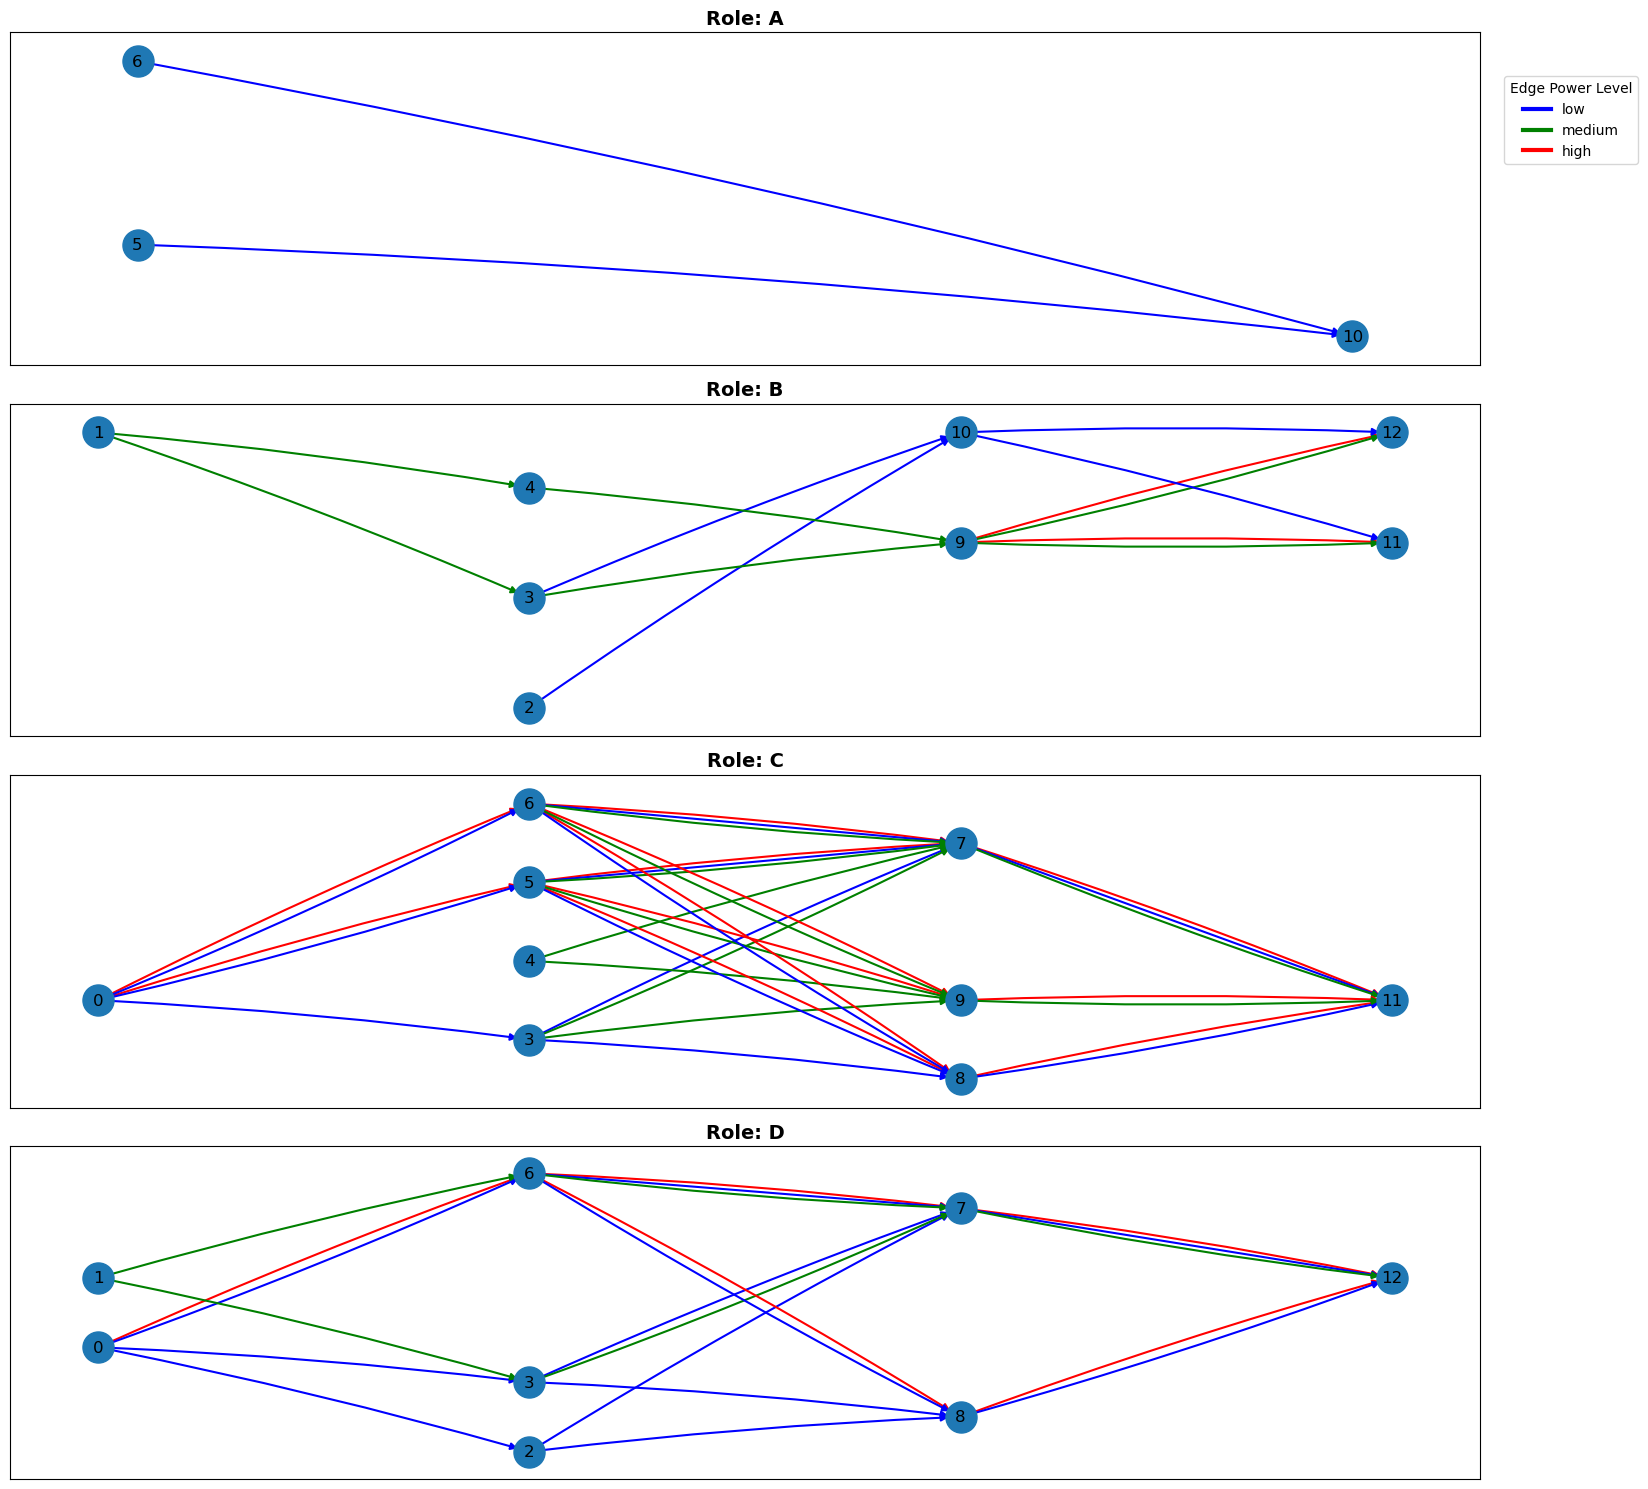

In [3]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def draw_power_edges(subgraph, pos, ax):

    POWER_COLORS = {"low": "blue","medium": "green","high": "red"}
    legend_used = set()
    for u, v, _ in subgraph.edges(data=True):
        u_power = set(subgraph.nodes[u].get("power", []))
        v_power = set(subgraph.nodes[v].get("power", []))
        shared = sorted(u_power & v_power)
        if not shared:
            shared = ["none"]
        radii = np.linspace(-0.02, 0.02, len(shared))
        for radius, power in zip(radii, shared):
            color = (POWER_COLORS[power]if power in POWER_COLORS else "gray")
            label = None
            if power not in legend_used:
                label = power
                legend_used.add(power)
            nx.draw_networkx_edges(
                subgraph, pos,edgelist=[(u, v)],edge_color=color,width=1.5,
                connectionstyle=f"arc3,rad={radius}",ax=ax,label=label
            )
    return legend_used

def draw_role_graphs(G):
    roles = sorted(list(set(role for n in G.nodes() for role in G.nodes[n]["role"])))
    pos = nx.multipartite_layout(G, subset_key="layer", align="vertical", scale=2)
    fig, axes = plt.subplots(len(roles), 1, figsize=(15, 15))
    if len(roles) == 1:
        axes = [axes]
    for ax, role in zip(axes, roles):
        subgraph = G.subgraph(n for n in G.nodes() if role in G.nodes[n]["role"])
        pos_sub = {n: pos[n] for n in subgraph.nodes()}
        _ = draw_power_edges(subgraph, pos_sub, ax)
        #nx.draw(subgraph,pos_sub,with_labels=True,node_size=500,ax=ax)
        nx.draw_networkx_nodes(subgraph, pos_sub, node_size=500, ax=ax)
        nx.draw_networkx_labels(subgraph, pos_sub, ax=ax)

        ax.set_title(f"Role: {role}", fontsize=14, fontweight="bold")
    legend_handles = [
    Line2D([0], [0], color="blue",  lw=3, label="low"),
    Line2D([0], [0], color="green", lw=3, label="medium"),
    Line2D([0], [0], color="red",   lw=3, label="high"),
    ]   
    fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(1.1, 0.95), title="Edge Power Level")
    plt.tight_layout()
    plt.show()

draw_role_graphs(G)

### Cyclic Graph to Layered DAG

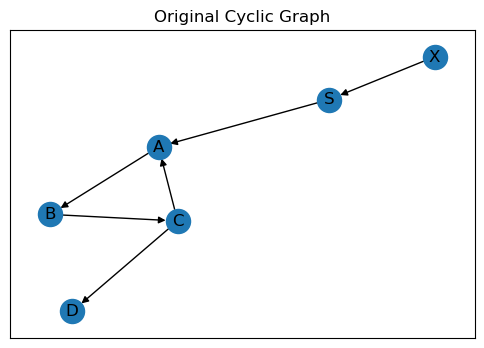

In [24]:
G = nx.DiGraph()

G.add_edges_from([
    ("X", "S"),
    ("S", "A"),
    ("A", "B"),
    ("B", "C"),
    ("C", "A"),
    ("C", "D"),
])

plt.figure(figsize=(6,4))
nx.draw_networkx(G)
plt.title("Original Cyclic Graph")
plt.show()

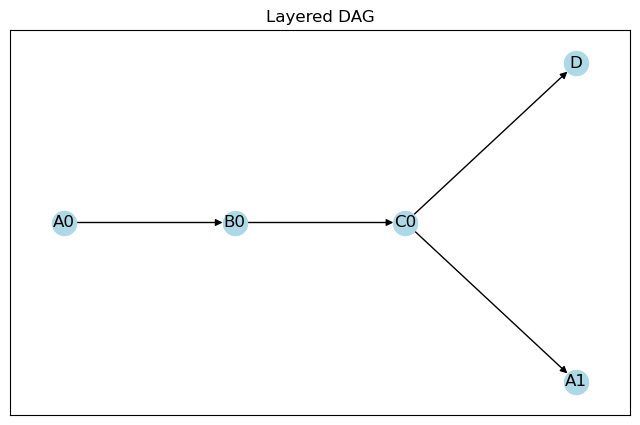

In [19]:
def longest_path_layers(G):
    layers = {}
    for node in nx.topological_sort(G):
        preds = list(G.predecessors(node))
        if not preds:
            layers[node] = 0
        else:
            layers[node] = max(layers[p] for p in preds) + 1
    return layers

layers = longest_path_layers(H)
for node, layer in layers.items():
    H.nodes[node]["layer"] = layer

pos = nx.multipartite_layout(H,subset_key="layer",align="vertical")
plt.figure(figsize=(8,5))
nx.draw_networkx(H, pos=pos,node_color="lightblue",arrows=True)
plt.title("Layered DAG")
plt.show()

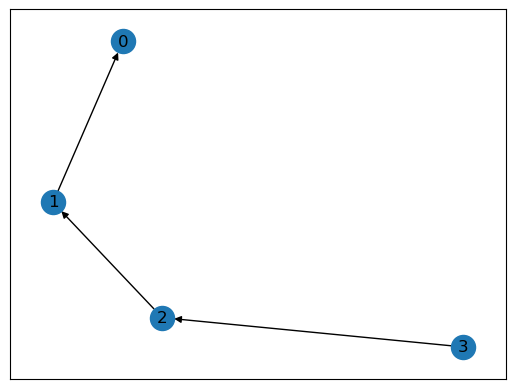

In [25]:
C = nx.condensation(G)
nx.draw_networkx(C, with_labels=True)

True


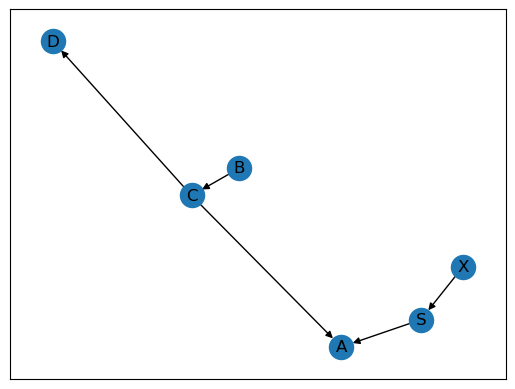

In [27]:
def representative_dag(G):
    H = nx.DiGraph()

    H.add_nodes_from(G.nodes(data=True))

    for scc in nx.strongly_connected_components(G):

        scc = list(scc)

        # SCC of size 1 cannot contain a cycle
        if len(scc) == 1:
            node = scc[0]

            for succ in G.successors(node):
                if succ != node:
                    H.add_edge(node, succ)

            continue

        root = scc[0]

        sub = G.subgraph(scc)

        tree = nx.dfs_tree(sub, source=root)

        H.add_edges_from(tree.edges())

    # Add all edges between SCCs
    comp_map = {}

    for i, scc in enumerate(nx.strongly_connected_components(G)):
        for node in scc:
            comp_map[node] = i

    for u, v in G.edges():

        if comp_map[u] != comp_map[v]:
            H.add_edge(u, v)

    return H
H = representative_dag(G)

print(nx.is_directed_acyclic_graph(H))
nx.draw_networkx(H, with_labels=True)